# Computer Vision — Project 4: Questions 1–3

**CS-GY 6643 · NYU Tandon · Fall 2026**

| Team member | NetID |
| --- | --- |
| TODO: enter name | TODO: enter NetID |

**AI assistance history:** TODO: add the actual shareable chat-history link or PDF reference before submission.

**Status — November 19, 2026 (America/New_York):** Q1–Q3 are implemented with intermediate views, final outputs, and correctness checks. Fill in team details and the actual AI-assistance history link before final submission.

This self-contained notebook will contain the code, visual outputs, and brief explanations for Questions 1–3. The assignment is specified in [Project4_CV.pdf](Project4_CV.pdf), pages 1–5. Q4 is maintained separately in `NYCGuessr.ipynb`.

## Notebook outline and execution

1. Shared setup and image-loading utilities.
2. **Q1 — Masked image reconstruction (15 points):** supplied masked RGB images and binary masks.
3. **Q2 — Patch-attention denoising (15 points):** coffee, cat, and astronaut noisy RGB images.
4. **Q3 — Frozen ViT object localization (20 points):** all 32 reference/scene pairs.
5. Input readiness and final submission checklist.

Keep this notebook beside the three data folders. On Colab or HPC, set `PROJECT_ROOT` in the next cell to the directory containing those folders. Data-loading cells read local inputs and display previews. Q1 and Q3 use pinned official MAE and DINOv2 checkpoints, downloading them only when their local caches are missing. There is no model training or writing to the data folders. All solution code will remain inline here.

```text
Project 4/
├── Project4_Q1_Q3.ipynb
├── Q1 Data/               # <name>_masked.png and <name>_mask.png
├── Q2 Data/               # <name>_noisy.png
└── Q3 Data/q3/
    ├── eval_001/           # reference.png and scene.png
    └── ... eval_032/
```

In [1]:
from pathlib import Path
from importlib.metadata import version
import platform
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Markdown, display

SEED = 6643
random.seed(SEED)
np.random.seed(SEED)

# Set a path here only if the kernel is not running in/under the project directory.
PROJECT_ROOT = None
DATA_FOLDER_NAMES = ("Q1 Data", "Q2 Data", "Q3 Data")

if PROJECT_ROOT is None:
    working_dir = Path.cwd().resolve()
    candidates = (working_dir, *working_dir.parents)
    PROJECT_ROOT = next(
        (candidate for candidate in candidates
         if all((candidate / name).is_dir() for name in DATA_FOLDER_NAMES)),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "Could not find Q1 Data, Q2 Data, and Q3 Data. "
            "Set PROJECT_ROOT to their parent directory and rerun this cell."
        )
else:
    PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()

DATA_DIRS = {f"q{i}": PROJECT_ROOT / name
             for i, name in enumerate(DATA_FOLDER_NAMES, start=1)}
for directory in DATA_DIRS.values():
    if not directory.is_dir():
        raise FileNotFoundError(f"Missing input folder: {directory}")

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})
print(f"Project root: {PROJECT_ROOT}")
print(f"Python {platform.python_version()} | NumPy {np.__version__} | "
      f"Pillow {version('Pillow')} | Matplotlib {version('matplotlib')}")
print(f"Seed: {SEED}")

Project root: /Users/rohitfarfad/Documents/NYU Coursework/Computer Vision/Project 4
Python 3.12.6 | NumPy 2.4.4 | Pillow 12.2.0 | Matplotlib 3.10.9
Seed: 6643


### Shared image contracts

RGB images are loaded as copied `uint8` arrays in **height × width × channels** order, with values in `[0, 255]`. Loading performs no resize, crop, normalization, or augmentation. Pillow dimensions are reported as **(width, height)**. Missing files, unexpected image modes, and inconsistent dimensions raise explicit errors.

In [2]:
def read_rgb(path: Path, expected_wh: tuple[int, int] | None = None) -> np.ndarray:
    """Decode an original RGB image into an independent H×W×3 uint8 array."""
    if not path.is_file():
        raise FileNotFoundError(f"Missing RGB image: {path}")
    with Image.open(path) as image:
        if image.mode != "RGB":
            raise ValueError(f"Expected RGB at {path}; found {image.mode}")
        if expected_wh is not None and image.size != expected_wh:
            raise ValueError(f"Expected size {expected_wh} at {path}; found {image.size}")
        return np.array(image, dtype=np.uint8, copy=True)


def show_table(rows: list[dict], columns: list[str]) -> None:
    """Display a compact inventory table using explicit column order."""
    header = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    body = ["| " + " | ".join(str(row[column]) for column in columns) + " |"
            for row in rows]
    display(Markdown("\n".join([header, separator, *body])))

## Q1 — Masked image reconstruction with a pretrained MAE

**Task.** Reconstruct the three 224×224 images using their supplied masks. Each mask removes 98 of 196 non-overlapping 16×16 patches. **White means missing; black means visible.** Missing patches must be excluded from the encoder-visible tokens, and visible pixels must remain unchanged in the final composite.

**Required results:** each supplied image beside its reconstruction, the pretrained model identity, and a short method explanation.

**Course reference:** Lecture 8 and `Class Resources/CodeLabs/Lecture_08_Self_Supervised_Learning_CLIP.ipynb`. Its random 75% masking demo must be adapted to the exact supplied 50% masks.

### Q1.1 — Load images and validate the patch masks

In [3]:
Q1_IMAGE_WH = (224, 224)
Q1_PATCH_SIZE = 16
q1_image_paths = sorted(DATA_DIRS["q1"].glob("*_masked.png"))
q1_names = [path.name.removesuffix("_masked.png") for path in q1_image_paths]
if set(q1_names) != {"bicycles", "bird", "street"} or len(q1_names) != 3:
    raise ValueError(f"Expected bicycles, bird, and street Q1 inputs; found {q1_names}")
expected_masks = {f"{name}_mask.png" for name in q1_names}
actual_masks = {path.name for path in DATA_DIRS["q1"].glob("*_mask.png")}
if actual_masks != expected_masks:
    raise ValueError(f"Q1 mask/image pairing mismatch: {actual_masks ^ expected_masks}")

q1_samples = []
for name, image_path in zip(q1_names, q1_image_paths):
    mask_path = DATA_DIRS["q1"] / f"{name}_mask.png"
    image_rgb = read_rgb(image_path, expected_wh=Q1_IMAGE_WH)
    with Image.open(mask_path) as mask_image:
        if mask_image.mode != "L" or mask_image.size != Q1_IMAGE_WH:
            raise ValueError(f"Expected a 224×224 grayscale mask: {mask_path}")
        mask_values = np.array(mask_image, dtype=np.uint8, copy=True)
    if not np.isin(mask_values, [0, 255]).all():
        raise ValueError(f"Mask must contain only black (0) and white (255): {mask_path}")

    missing_mask = mask_values == 255
    grid_h = image_rgb.shape[0] // Q1_PATCH_SIZE
    grid_w = image_rgb.shape[1] // Q1_PATCH_SIZE
    blocks = missing_mask.reshape(grid_h, Q1_PATCH_SIZE, grid_w, Q1_PATCH_SIZE)
    blocks = blocks.transpose(0, 2, 1, 3)
    patch_mask = blocks[:, :, 0, 0].copy()
    if not np.all(blocks == patch_mask[:, :, None, None]):
        raise ValueError(f"Mask boundaries do not align to the 16×16 patch grid: {mask_path}")
    if int(patch_mask.sum()) != 98:
        raise ValueError(f"Expected 98 missing patches: {mask_path}")

    q1_samples.append({
        "sample_id": name,
        "image_path": image_path,
        "mask_path": mask_path,
        "image_rgb": image_rgb,
        "missing_mask": missing_mask,  # H×W bool: True means missing.
        "patch_mask": patch_mask,      # 14×14 bool in row-major image order.
    })

show_table([
    {"sample": sample["sample_id"], "RGB shape (H,W,C)": sample["image_rgb"].shape,
     "missing patches": int(sample["patch_mask"].sum()),
     "total patches": sample["patch_mask"].size,
     "missing pixels": f"{sample['missing_mask'].mean():.0%}"}
    for sample in q1_samples
], ["sample", "RGB shape (H,W,C)", "missing patches", "total patches", "missing pixels"])

| sample | RGB shape (H,W,C) | missing patches | total patches | missing pixels |
| --- | --- | --- | --- | --- |
| bicycles | (224, 224, 3) | 98 | 196 | 50% |
| bird | (224, 224, 3) | 98 | 196 | 50% |
| street | (224, 224, 3) | 98 | 196 | 50% |

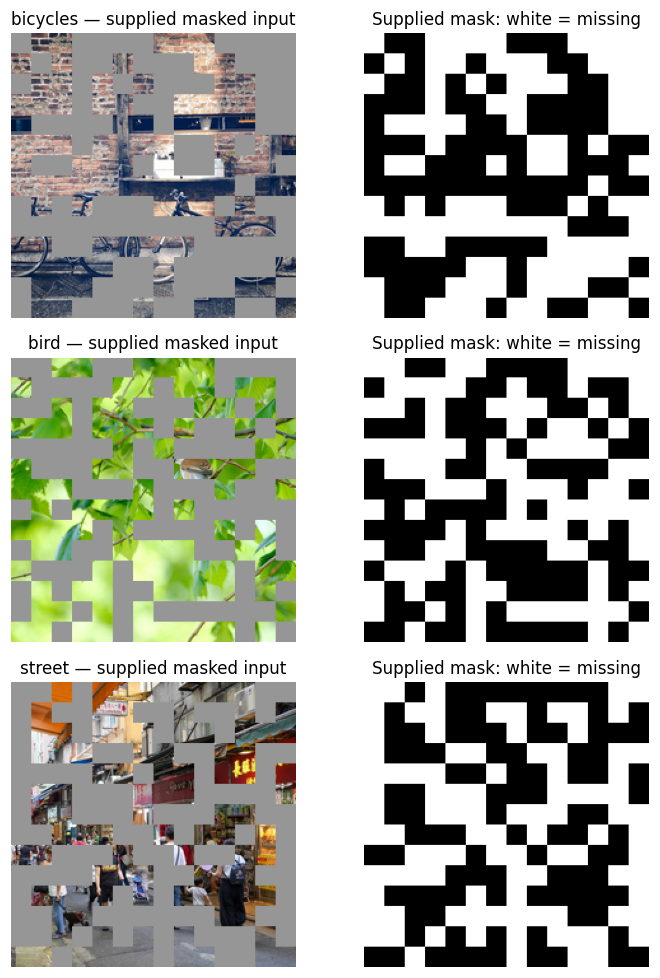

In [4]:
fig, axes = plt.subplots(len(q1_samples), 2, figsize=(7, 9), squeeze=False)
for row, sample in enumerate(q1_samples):
    axes[row, 0].imshow(sample["image_rgb"])
    axes[row, 0].set_title(f"{sample['sample_id']} — supplied masked input")
    axes[row, 1].imshow(sample["missing_mask"], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Supplied mask: white = missing")
for axis in axes.flat:
    axis.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

### Q1.2 — Pretrained model and preprocessing

We use **[facebook/vit-mae-base](https://huggingface.co/facebook/vit-mae-base)**, a ViT-B/16 masked autoencoder pretrained on ImageNet-1K without class labels. Its 12-block encoder processes visible patches; its 8-block decoder predicts RGB patch pixels. We freeze the complete model and run inference on CPU in float32.

The supplied images already have the required 224×224 size. Preprocessing rescales RGB to `[0,1]` and applies the checkpoint's channel mean and standard deviation, with **no resizing or cropping**. The first run downloads about 448 MB of official weights into the project's ignored `outputs/models/` folder. Later runs reuse them. The pinned revision and SHA-256 below identify the exact checkpoint.

References: [He et al., MAE](https://github.com/facebookresearch/mae), [Transformers ViTMAE documentation](https://huggingface.co/docs/transformers/model_doc/vit_mae), and Lecture 8's MAE codelab.

In [5]:
import hashlib
import time
import torch
from huggingface_hub import snapshot_download
from transformers import ViTImageProcessor, ViTMAEForPreTraining

Q1_MODEL_ID = "facebook/vit-mae-base"
Q1_REVISION = "25b184bea5538bf5c4c852c79d221195fdd2778d"
Q1_WEIGHTS_SHA256 = "479dcef4bd5df06259399027b789f21e9d9a1b79f37155a64176d55bc26fdae8"
Q1_MODEL_DIR = PROJECT_ROOT / "outputs" / "models" / f"vit_mae_base_{Q1_REVISION[:12]}"
q1_files = ["config.json", "preprocessor_config.json", "model.safetensors"]
if not all((Q1_MODEL_DIR / name).is_file() for name in q1_files):
    snapshot_download(Q1_MODEL_ID, revision=Q1_REVISION, local_dir=Q1_MODEL_DIR,
                      allow_patterns=q1_files, token=False, max_workers=1)
with (Q1_MODEL_DIR / "model.safetensors").open("rb") as stream:
    q1_weights_hash = hashlib.file_digest(stream, "sha256").hexdigest()
assert q1_weights_hash == Q1_WEIGHTS_SHA256, "MAE checkpoint hash mismatch"

torch.set_num_threads(min(4, torch.get_num_threads()))
q1_processor = ViTImageProcessor.from_pretrained(Q1_MODEL_DIR, local_files_only=True)
q1_model = ViTMAEForPreTraining.from_pretrained(
    Q1_MODEL_DIR, local_files_only=True, use_safetensors=True, attn_implementation="eager"
).eval().requires_grad_(False)
q1_model.config.mask_ratio = 0.5
assert (q1_model.config.image_size, q1_model.config.patch_size) == (224, 16)
assert not q1_model.config.norm_pix_loss, "This decoder must predict channel-normalized pixels"
q1_mean = torch.tensor(q1_processor.image_mean).view(1, 3, 1, 1)
q1_std = torch.tensor(q1_processor.image_std).view(1, 3, 1, 1)
print(f"Checkpoint: {Q1_MODEL_ID} @ {Q1_REVISION}")
print(f"SHA-256: {q1_weights_hash}")
print(f"PyTorch {torch.__version__} | Transformers {version('transformers')} | "
      f"CPU float32, {torch.get_num_threads()} threads")
print(f"Channel mean: {q1_processor.image_mean}; std: {q1_processor.image_std}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1119 23:26:19.625000 52186 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Checkpoint: facebook/vit-mae-base @ 25b184bea5538bf5c4c852c79d221195fdd2778d
SHA-256: 479dcef4bd5df06259399027b789f21e9d9a1b79f37155a64176d55bc26fdae8
PyTorch 2.11.0 | Transformers 5.23.0 | CPU float32, 4 threads
Channel mean: (0.485, 0.456, 0.406); std: (0.229, 0.224, 0.225)


### Q1.3 — Reconstruction flow

This diagram shows the actual tensor sizes for one supplied image; batch dimensions are omitted. Patch embeddings keep their original positional encodings. **Only 98 visible patch tokens plus CLS enter the encoder's transformer blocks.** The decoder inserts learned mask tokens and restores the 196 spatial patch positions before predicting pixels.

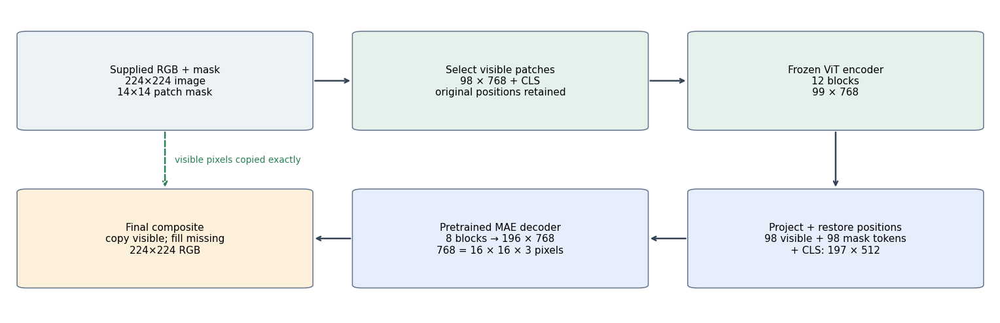

In [6]:
from matplotlib.patches import FancyBboxPatch

cfg = q1_model.config
fig, ax = plt.subplots(figsize=(14, 4.6))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")
nodes = [
    (0.16, 0.76, "Supplied RGB + mask\n224×224 image\n14×14 patch mask", "#edf2f7"),
    (0.50, 0.76, f"Select visible patches\n98 × {cfg.hidden_size} + CLS\noriginal positions retained", "#e4f2eb"),
    (0.84, 0.76, f"Frozen ViT encoder\n{cfg.num_hidden_layers} blocks\n99 × {cfg.hidden_size}", "#e4f2eb"),
    (0.84, 0.25, f"Project + restore positions\n98 visible + 98 mask tokens\n+ CLS: 197 × {cfg.decoder_hidden_size}", "#e7eefb"),
    (0.50, 0.25, f"Pretrained MAE decoder\n{cfg.decoder_num_hidden_layers} blocks → 196 × 768\n768 = 16 × 16 × 3 pixels", "#e7eefb"),
    (0.16, 0.25, "Final composite\ncopy visible; fill missing\n224×224 RGB", "#fdf0da"),
]
for x, y, label, color in nodes:
    ax.add_patch(FancyBboxPatch((x - .14, y - .15), .28, .30,
                 boxstyle="round,pad=0.01", facecolor=color, edgecolor="#63748b"))
    ax.text(x, y, label, ha="center", va="center", fontsize=10)
for start, end in [((.31, .76), (.35, .76)), ((.65, .76), (.69, .76)),
                   ((.84, .60), (.84, .41)), ((.69, .25), (.65, .25)),
                   ((.35, .25), (.31, .25))]:
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="#344256", lw=1.6))
ax.annotate("", xy=(.16, .41), xytext=(.16, .60),
            arrowprops=dict(arrowstyle="->", color="#278154", lw=1.6, linestyle="--"))
ax.text(.17, .505, "visible pixels copied exactly", color="#278154", va="center", fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)

### Q1.4 — Encode visible patches and reconstruct

For patch index $i$ and supplied missing-mask value $m_i\in\{0,1\}$, use the unique ordering key $s_i=i+196m_i$. All visible patches sort before all missing patches. Setting the keep fraction to 50% therefore selects **exactly the supplied 98 visible patches**; the model also returns the inverse permutation used by its decoder.

The decoder predicts channel-normalized pixels. We reverse channel normalization, clip generated RGB values to `[0,1]`, and round to `uint8`. For pixel mask $M$ (1 = missing), the final image is

$$I_{\mathrm{final}}=(1-M)\odot I_{\mathrm{supplied}}+M\odot I_{\mathrm{predicted}}.$$

Implementation copies the supplied byte values first, then assigns predictions only inside the mask. There is no reconstruction-loss evaluation against the gray placeholders.

In [7]:
@torch.inference_mode()
def predict_q1(image_rgb: np.ndarray, patch_mask: np.ndarray) -> tuple[np.ndarray, tuple]:
    """Return predicted RGB floats and encoder shape using the exact supplied mask."""
    missing = torch.from_numpy(patch_mask.ravel()).bool()
    order_key = (torch.arange(missing.numel()) + missing * missing.numel()).float()[None]
    pixels = q1_processor(images=image_rgb, do_resize=False, return_tensors="pt")["pixel_values"]
    encoded = q1_model.vit(pixel_values=pixels, noise=order_key)
    assert torch.equal(encoded.mask[0].bool(), missing), "Encoder used the wrong mask"
    encoder_shape = tuple(encoded.last_hidden_state.shape)
    assert encoder_shape == (1, 99, q1_model.config.hidden_size)
    decoded = q1_model.decoder(encoded.last_hidden_state, encoded.ids_restore)
    assert tuple(decoded.logits.shape) == (1, 196, 16 * 16 * 3)
    prediction = q1_model.unpatchify(decoded.logits) * q1_std + q1_mean
    assert torch.isfinite(prediction).all(), "Non-finite decoder output"
    return prediction[0].permute(1, 2, 0).numpy(), encoder_shape


q1_started = time.perf_counter()
q1_results = []
for sample in q1_samples:
    raw_prediction, encoder_shape = predict_q1(sample["image_rgb"], sample["patch_mask"])
    predicted_rgb = np.rint(np.clip(raw_prediction, 0, 1) * 255).astype(np.uint8)
    completed_rgb = sample["image_rgb"].copy()
    completed_rgb[sample["missing_mask"]] = predicted_rgb[sample["missing_mask"]]
    q1_results.append({"sample_id": sample["sample_id"], "raw_prediction": raw_prediction,
                       "predicted_rgb": predicted_rgb, "completed_rgb": completed_rgb,
                       "encoder_shape": encoder_shape})
q1_inference_seconds = time.perf_counter() - q1_started
print(f"Reconstructed {len(q1_results)} images in {q1_inference_seconds:.2f}s (CPU).")

Reconstructed 3 images in 0.26s (CPU).


### Q1.5 — Intermediate outputs

**Left:** the supplied 14×14 missing-patch mask. **Middle:** only the 98 visible patches, packed in their encoder order for display; their original positions are still represented by positional embeddings inside the model. **Right:** the decoder's prediction at all patch positions, before copying the known pixels back. Decoder estimates at visible locations are shown for inspection; the final composite uses the original visible pixels.

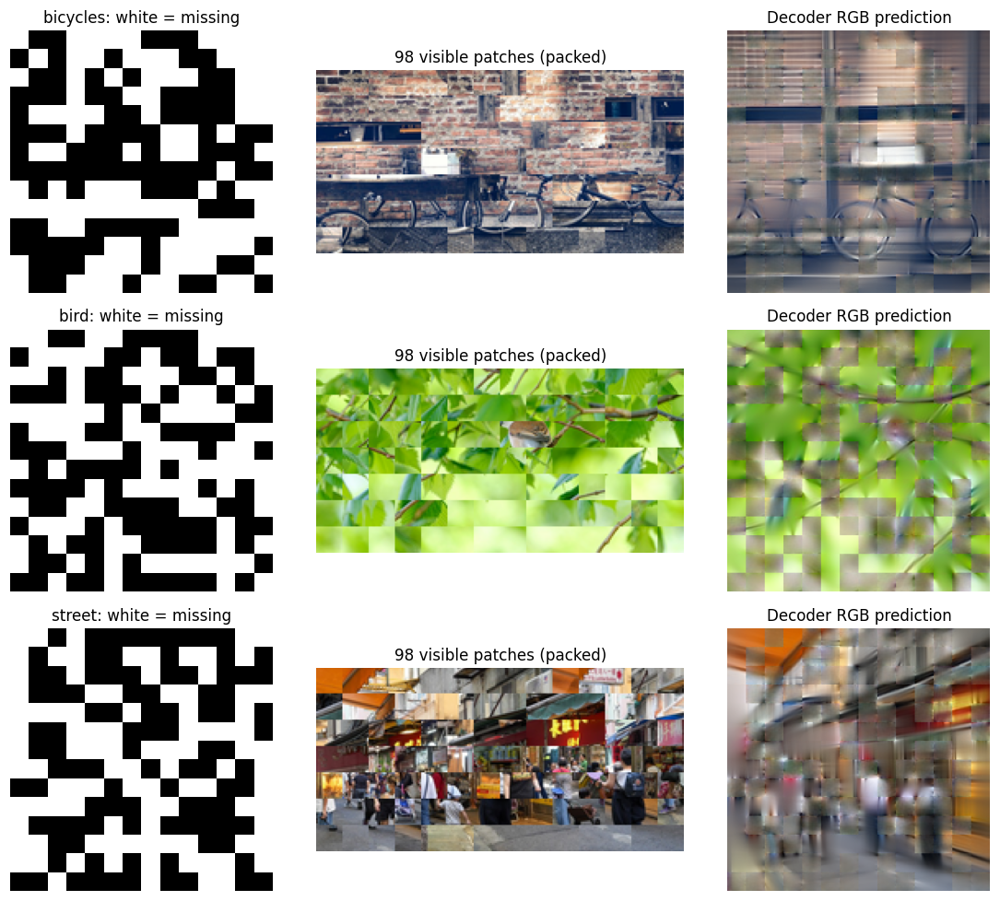

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for row, (sample, result) in enumerate(zip(q1_samples, q1_results)):
    patches = sample["image_rgb"].reshape(14, 16, 14, 16, 3).transpose(0, 2, 1, 3, 4)
    visible = patches.reshape(196, 16, 16, 3)[~sample["patch_mask"].ravel()]
    packed = visible.reshape(7, 14, 16, 16, 3).transpose(0, 2, 1, 3, 4).reshape(112, 224, 3)
    axes[row, 0].imshow(sample["patch_mask"], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[row, 0].set_title(f"{sample['sample_id']}: white = missing")
    axes[row, 1].imshow(packed)
    axes[row, 1].set_title("98 visible patches (packed)")
    axes[row, 2].imshow(result["predicted_rgb"])
    axes[row, 2].set_title("Decoder RGB prediction")
for axis in axes.flat:
    axis.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

### Q1.6 — Final reconstructions

Each completed image below combines original visible pixels with MAE predictions in the supplied missing regions. These are inferred completions; no unmasked target images are supplied for comparison.

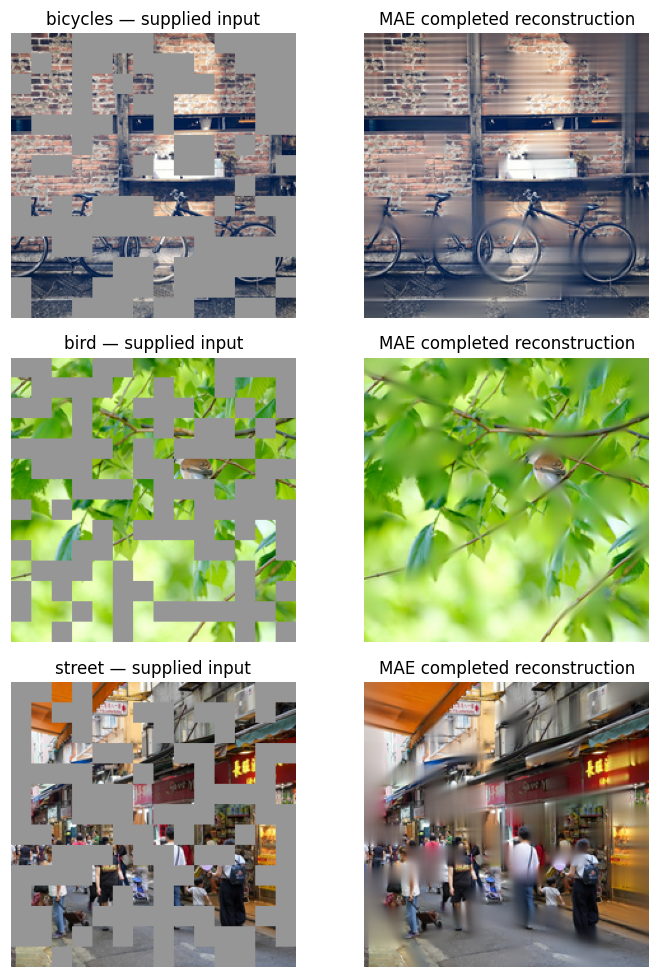

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(7, 9))
for row, (sample, result) in enumerate(zip(q1_samples, q1_results)):
    axes[row, 0].imshow(sample["image_rgb"])
    axes[row, 0].set_title(f"{sample['sample_id']} — supplied input")
    axes[row, 1].imshow(result["completed_rgb"])
    axes[row, 1].set_title("MAE completed reconstruction")
for axis in axes.flat:
    axis.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

### Q1.7 — Correctness checks

For each image, verify that visible pixels are byte-for-byte unchanged and every missing pixel comes from the decoder. Then replace all input pixels inside the holes with random RGB values and rerun inference. The raw prediction must remain unchanged: this checks that hidden placeholder contents cannot influence reconstruction through the encoder.

These checks establish mask and compositing correctness. They do not measure reconstruction accuracy; the original hidden pixels are unavailable.

In [10]:
q1_checks = []
q1_rng = np.random.default_rng(SEED)
for sample, result in zip(q1_samples, q1_results):
    missing = sample["missing_mask"]
    completed = result["completed_rgb"]
    assert completed.shape == sample["image_rgb"].shape and completed.dtype == np.uint8
    assert np.array_equal(completed[~missing], sample["image_rgb"][~missing])
    assert np.array_equal(completed[missing], result["predicted_rgb"][missing])
    altered = sample["image_rgb"].copy()
    altered[missing] = q1_rng.integers(0, 256, size=(int(missing.sum()), 3), dtype=np.uint8)
    altered_prediction, _ = predict_q1(altered, sample["patch_mask"])
    hidden_delta = float(np.abs(altered_prediction - result["raw_prediction"]).max())
    assert hidden_delta == 0.0, "Hidden pixels influenced the prediction"
    q1_checks.append({"image": sample["sample_id"], "visible patches": 98,
                      "encoder shape (B,T,D)": result["encoder_shape"],
                      "changed visible pixels": int(np.any(completed != sample["image_rgb"], axis=2)[~missing].sum()),
                      "hidden-fill prediction change": hidden_delta})
assert not q1_model.training and not any(p.requires_grad for p in q1_model.parameters())
show_table(q1_checks, ["image", "visible patches", "encoder shape (B,T,D)",
                       "changed visible pixels", "hidden-fill prediction change"])
print("All three images passed exact-mask, token-shape, compositing, and hidden-pixel invariance checks.")

| image | visible patches | encoder shape (B,T,D) | changed visible pixels | hidden-fill prediction change |
| --- | --- | --- | --- | --- |
| bicycles | 98 | (1, 99, 768) | 0 | 0.0 |
| bird | 98 | (1, 99, 768) | 0 | 0.0 |
| street | 98 | (1, 99, 768) | 0 | 0.0 |

All three images passed exact-mask, token-shape, compositing, and hidden-pixel invariance checks.


### Q1.8 — Discussion

- **Bicycles:** the completion continues brick colors and bicycle outlines; some wall and wheel regions remain soft.
- **Bird:** foliage and branches continue through the holes, while small bird and leaf details remain uncertain.
- **Street:** the model continues the building and awning layout; generated people and lettering are blurred.

These are visual observations, not comparisons with hidden ground truth. All visible pixels are preserved exactly. MAE supplies plausible missing structure, with smooth estimates where detail is ambiguous. Original unmasked targets are unavailable, so no PSNR/SSIM or numerical reconstruction-accuracy claim is made.

## Q2 — Image denoising using patch attention

**Task.** Apply a patch-attention method to the complete noisy RGB images while preserving colors, edges, and fine detail.

| Image | Supplied noise |
| --- | --- |
| Coffee | Gaussian and salt-and-pepper |
| Cat | Poisson |
| Astronaut | Gaussian and horizontal banding |

**Required results:** noisy/denoised pairs and one computed attention heatmap per image showing which image regions contribute to a selected patch. Explain the contributors using the weights actually used by the denoiser.

**Course reference:** Lecture 9's non-local means and attention formulation, and `Class Resources/CodeLabs/Codelab_attention.ipynb` for attention visualization. That codelab is not a complete patch-attention denoiser.

### Q2.1 — Load the complete noisy images

In [11]:
Q2_NOISE = {
    "coffee": "Gaussian + salt-and-pepper",
    "cat": "Poisson",
    "astronaut": "Gaussian + horizontal banding",
}
expected_files = {f"{name}_noisy.png" for name in Q2_NOISE}
actual_files = {path.name for path in DATA_DIRS["q2"].glob("*_noisy.png")}
if actual_files != expected_files:
    raise ValueError(f"Q2 input inventory mismatch: {actual_files ^ expected_files}")

q2_samples = []
for name, noise in Q2_NOISE.items():
    image_path = DATA_DIRS["q2"] / f"{name}_noisy.png"
    q2_samples.append({
        "sample_id": name,
        "image_path": image_path,
        "image_rgb": read_rgb(image_path, expected_wh=(512, 512)),
        "noise": noise,
    })

show_table([
    {"sample": sample["sample_id"], "RGB shape (H,W,C)": sample["image_rgb"].shape,
     "dtype": str(sample["image_rgb"].dtype), "noise": sample["noise"]}
    for sample in q2_samples
], ["sample", "RGB shape (H,W,C)", "dtype", "noise"])

| sample | RGB shape (H,W,C) | dtype | noise |
| --- | --- | --- | --- |
| coffee | (512, 512, 3) | uint8 | Gaussian + salt-and-pepper |
| cat | (512, 512, 3) | uint8 | Poisson |
| astronaut | (512, 512, 3) | uint8 | Gaussian + horizontal banding |

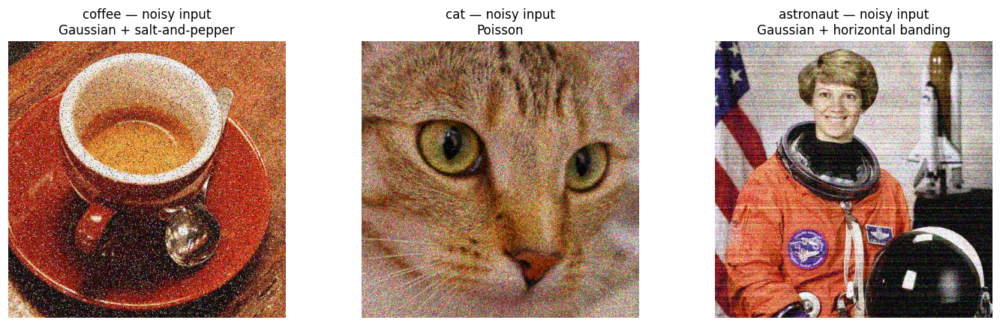

In [12]:
fig, axes = plt.subplots(1, len(q2_samples), figsize=(13, 4), squeeze=False)
for axis, sample in zip(axes[0], q2_samples):
    axis.imshow(sample["image_rgb"])
    axis.set_title(f"{sample['sample_id']} — noisy input\n{sample['noise']}")
    axis.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

### Q2.2 — Method: local patch attention

We implement a non-local-means-style **patch-attention** denoiser. Each overlapping 8×8 RGB patch (stride 2) is a query. Its 9×9 neighborhood of patch centers supplies up to 81 keys and value patches. A lightly smoothed guide supplies matching features; the prepared RGB patches supply values. With patch mean-square distance $d_{ij}$,

$$a_{ij}=\operatorname{softmax}_{j\in\mathcal N(i)}(-d_{ij}/h^2),\qquad
\widehat P_i=\sum_j a_{ij}P_j.$$

We cap the self-match at the best non-self match, preventing a noisy query from receiving all the weight. Overlapping patch estimates are averaged back into the **complete 512×512 image**. Queries run in chunks of 256; no all-image attention matrix is built.

Noise-specific preparation follows the stated noise types: replace strong clipped impulses in coffee with local medians; use a square-root matching guide for Poisson-noisy cat; estimate and subtract robust row offsets for astronaut banding. All three then use the same patch-attention implementation. Bandwidth is 0.55 times the input's diagonal high-frequency noise estimate, with a 0.04 floor in guide units. These are explicit heuristics, with no clean target used for tuning.

Reference: [Buades, Coll & Morel, Non-Local Means](https://www.ipol.im/pub/art/2011/bcm_nlm/) and Lecture 9's content-dependent weighting analogy.

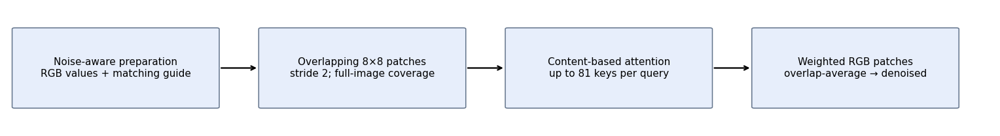

In [13]:
import torch.nn.functional as F
from scipy import ndimage as ndi


def pipeline_diagram(labels):
    """Draw the actual stages of a notebook method."""
    fig, ax = plt.subplots(figsize=(14, 2))
    ax.set(xlim=(0, len(labels)), ylim=(0, 1)); ax.axis("off")
    for i, label in enumerate(labels):
        ax.add_patch(FancyBboxPatch((i + .03, .18), .82, .64,
                     boxstyle="round,pad=.01", facecolor="#e7eefb", edgecolor="#63748b"))
        ax.text(i + .44, .5, label, ha="center", va="center", fontsize=10)
        if i + 1 < len(labels):
            ax.annotate("", xy=(i + 1.02, .5), xytext=(i + .86, .5),
                        arrowprops=dict(arrowstyle="->", lw=1.5))
    fig.tight_layout(); plt.show(); plt.close(fig)


pipeline_diagram(["Noise-aware preparation\nRGB values + matching guide",
                  "Overlapping 8×8 patches\nstride 2; full-image coverage",
                  "Content-based attention\nup to 81 keys per query",
                  "Weighted RGB patches\noverlap-average → denoised"])

In [14]:
def prepare_q2(image_rgb: np.ndarray, noise_kind: str) -> tuple[np.ndarray, np.ndarray, float]:
    values = image_rgb.astype(np.float32) / 255
    if noise_kind == "coffee":
        median = ndi.median_filter(values, size=(3, 3, 1))
        impulses = ((values <= 1/255) | (values >= 254/255)) & (np.abs(values - median) > .25)
        values = np.where(impulses, median, values)
    elif noise_kind == "astronaut":
        row_bias = np.median(values - ndi.median_filter(values, size=(7, 1, 1)), axis=1, keepdims=True)
        values = np.clip(values - row_bias, 0, 1)
    metric = np.sqrt(values + 1/255) if noise_kind == "cat" else values
    guide = ndi.gaussian_filter(metric, sigma=(.8, .8, 0))
    hh = (metric[::2, ::2] - metric[1::2, ::2] - metric[::2, 1::2] + metric[1::2, 1::2]) / 2
    bandwidth = max(.04, .55 * float(np.median(np.abs(hh)) / .67449))
    return values, guide, bandwidth


@torch.inference_mode()
def patch_attention_denoise(values, guide, bandwidth, patch=8, stride=2, radius=4, chunk=256):
    """Attention on RGB patches, with bounded candidate gathers and overlap averaging."""
    height, width = values.shape[:2]
    assert (height - patch) % stride == (width - patch) % stride == 0
    to_tensor = lambda x: torch.from_numpy(np.ascontiguousarray(x)).permute(2, 0, 1)[None]
    value_patches = F.unfold(to_tensor(values), patch, stride=stride)[0].T
    guide_patches = F.unfold(to_tensor(guide), patch, stride=stride)[0].T
    gh, gw = (height - patch)//stride + 1, (width - patch)//stride + 1
    offsets = torch.cartesian_prod(torch.arange(-radius, radius+1), torch.arange(-radius, radius+1))
    self_index = len(offsets)//2
    selected = (gh//2) * gw + gw//2
    estimates = torch.empty_like(value_patches)
    max_sum_error = 0.0
    for start in range(0, len(value_patches), chunk):
        ids = torch.arange(start, min(start + chunk, len(value_patches)))
        rows, cols = ids//gw, ids%gw
        rr, cc = rows[:, None] + offsets[:, 0], cols[:, None] + offsets[:, 1]
        valid = (rr >= 0) & (rr < gh) & (cc >= 0) & (cc < gw)
        neighbors = rr.clamp(0, gh-1)*gw + cc.clamp(0, gw-1)
        distance = ((guide_patches[ids, None] - guide_patches[neighbors])**2).mean(-1)
        distance[~valid] = torch.inf
        distance[:, self_index] = torch.inf
        distance[:, self_index] = distance.min(1).values
        weights = torch.softmax(-distance / bandwidth**2, dim=1)
        estimates[ids] = torch.einsum("bk,bkd->bd", weights, value_patches[neighbors])
        max_sum_error = max(max_sum_error, float((weights.sum(1)-1).abs().max()))
        if start <= selected < start + len(ids):
            k = selected - start
            attention = {"weights": weights[k].numpy().copy(),
                         "rows": rr[k].numpy(), "cols": cc[k].numpy(),
                         "valid": valid[k].numpy(), "query_rc": (gh//2, gw//2),
                         "estimate": estimates[selected].numpy().copy()}
    columns = estimates.T[None].contiguous()
    coverage = F.fold(torch.ones(1, patch*patch, gh*gw), (height, width), patch, stride=stride)
    assert float(coverage.min()) > 0, "Uncovered output pixels"
    denoised = (F.fold(columns, (height, width), patch, stride=stride) / coverage)[0]
    attention.update({"patch": patch, "stride": stride, "radius": radius,
                      "max_weight_sum_error": max_sum_error, "min_coverage": float(coverage.min())})
    return denoised.permute(1, 2, 0).numpy().clip(0, 1), attention


q2_started = time.perf_counter()
q2_results = []
for sample in q2_samples:
    values, guide, bandwidth = prepare_q2(sample["image_rgb"], sample["sample_id"])
    denoised, attention = patch_attention_denoise(values, guide, bandwidth)
    q2_results.append({"sample_id": sample["sample_id"], "prepared": values,
                       "denoised": denoised, "attention": attention, "bandwidth": bandwidth})
q2_seconds = time.perf_counter() - q2_started
print(f"Denoised all three full images in {q2_seconds:.2f}s on CPU.")

Denoised all three full images in 3.13s on CPU.


### Q2.3 — Intermediate preparation and final denoised images

The middle column shows the noise-specific preparation; the last column is the full patch-attention reconstruction. Matching uses a smoothed guide, but output values come from RGB patches. Identical attention weights are applied to all three channels to keep colors aligned.

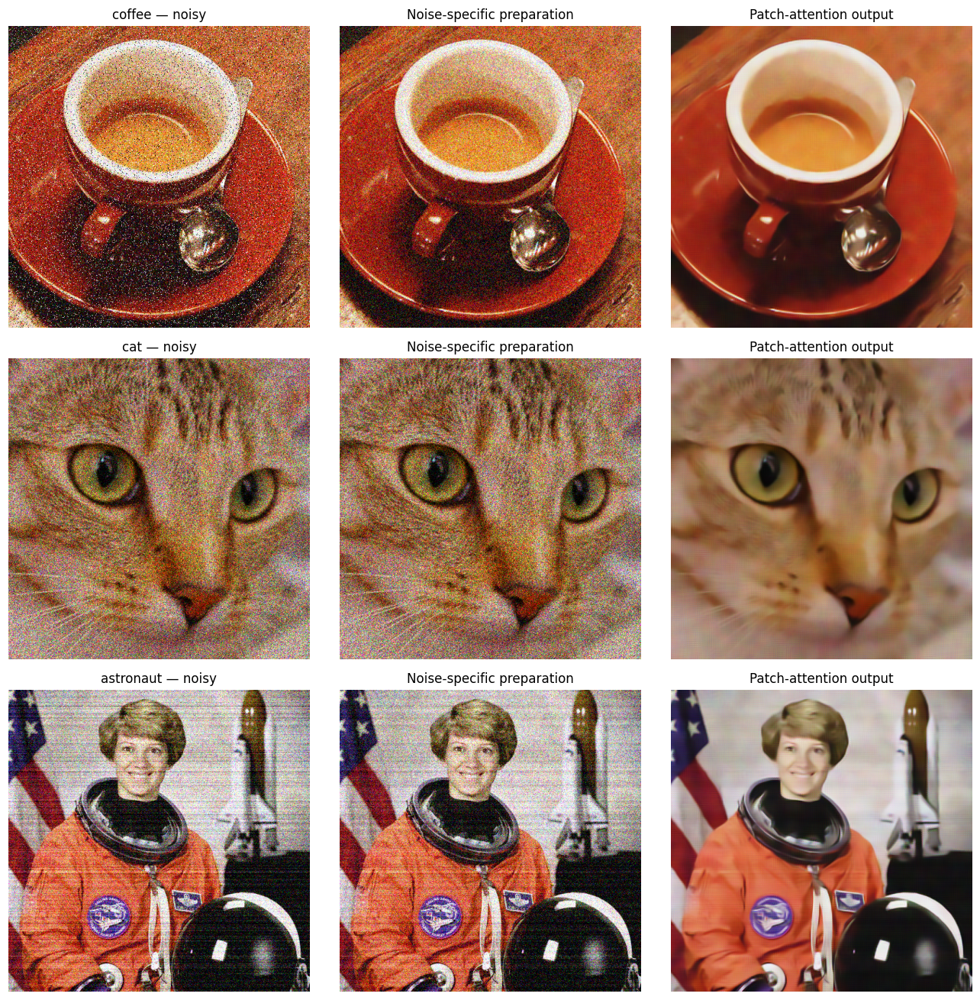

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, (sample, result) in enumerate(zip(q2_samples, q2_results)):
    for col, (image, title) in enumerate([(sample["image_rgb"], f"{sample['sample_id']} — noisy"),
                                        (result["prepared"], "Noise-specific preparation"),
                                        (result["denoised"], "Patch-attention output")]):
        axes[row, col].imshow(image); axes[row, col].set_title(title); axes[row, col].axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

### Q2.4 — Actual attention weights for one query patch per image

The red box selects the central 8×8 query. The middle panel magnifies its search region; the last panel shows the **stored weights used to reconstruct that query patch**, indexed by candidate patch centers. Bright cells contributed more. They are not ViT saliency or decorative weights. The final image additionally averages overlapping reconstructed patches.

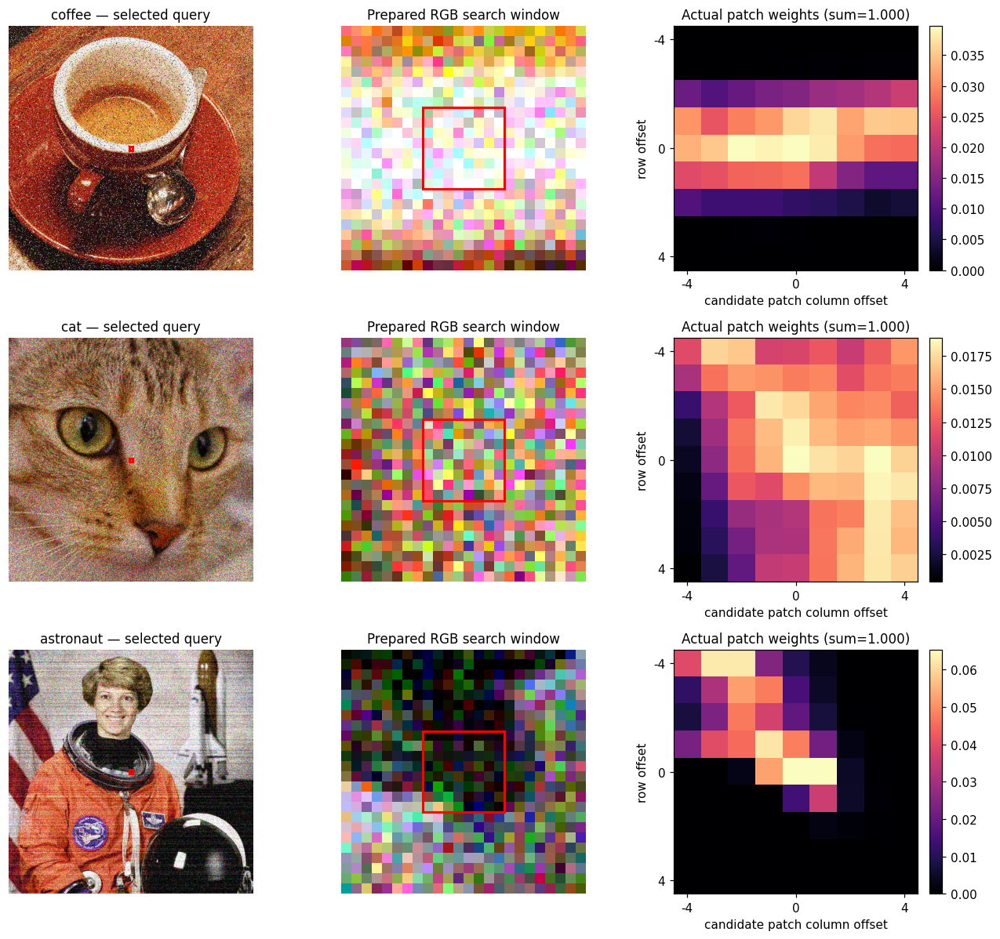

In [16]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for row, (sample, result) in enumerate(zip(q2_samples, q2_results)):
    a = result["attention"]; p, s, r = a["patch"], a["stride"], a["radius"]
    qr, qc = a["query_rc"]; y, x = qr*s, qc*s
    left, top, right, bottom = x-r*s, y-r*s, x+r*s+p, y+r*s+p
    axes[row, 0].imshow(sample["image_rgb"])
    axes[row, 0].add_patch(Rectangle((x, y), p, p, fill=False, edgecolor="red", lw=2))
    axes[row, 0].set_title(f"{sample['sample_id']} — selected query")
    axes[row, 1].imshow(result["prepared"][top:bottom, left:right], extent=(left, right, bottom, top))
    axes[row, 1].add_patch(Rectangle((x, y), p, p, fill=False, edgecolor="red", lw=2))
    axes[row, 1].set_title("Prepared RGB search window")
    im = axes[row, 2].imshow(a["weights"].reshape(2*r+1, 2*r+1), cmap="magma", interpolation="nearest")
    axes[row, 2].set_title(f"Actual patch weights (sum={a['weights'].sum():.3f})")
    axes[row, 2].set_xlabel("candidate patch column offset"); axes[row, 2].set_ylabel("row offset")
    axes[row, 2].set_xticks([0, r, 2*r], [-r, 0, r]); axes[row, 2].set_yticks([0, r, 2*r], [-r, 0, r])
    fig.colorbar(im, ax=axes[row, 2], fraction=.046, pad=.04)
    for axis in axes[row, :2]: axis.axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

### Q2.5 — Checks and limitations

Check full-image coverage, finite RGB outputs, normalized nonnegative weights, exact replay of the selected weighted patch, and preservation of a constant-color image. These establish implementation correctness. Clean target images are unavailable, so PSNR/SSIM and reconstruction-accuracy claims are omitted.

In [17]:
q2_checks = []
for sample, result in zip(q2_samples, q2_results):
    a = result["attention"]; p, s = a["patch"], a["stride"]
    weights = a["weights"]; assert (weights >= 0).all() and np.allclose(weights.sum(), 1)
    assert np.isfinite(result["denoised"]).all() and result["denoised"].shape == sample["image_rgb"].shape
    replay = np.zeros(3*p*p, dtype=np.float32)
    for weight, rr, cc, valid in zip(weights, a["rows"], a["cols"], a["valid"]):
        if valid:
            replay += weight * result["prepared"][rr*s:rr*s+p, cc*s:cc*s+p].transpose(2, 0, 1).ravel()
    replay_error = float(np.max(np.abs(replay - a["estimate"])))
    assert replay_error < 1e-6 and a["max_weight_sum_error"] < 1e-6
    q2_checks.append({"image": sample["sample_id"], "bandwidth": round(result["bandwidth"], 4),
                      "min overlap coverage": a["min_coverage"],
                      "weight sum error": a["max_weight_sum_error"], "replay error": replay_error})
constant = np.full((32, 32, 3), .4, dtype=np.float32)
constant_out, _ = patch_attention_denoise(constant, constant, .05)
assert np.allclose(constant_out, constant, atol=1e-6), "Constant color was not preserved"
show_table(q2_checks, ["image", "bandwidth", "min overlap coverage", "weight sum error", "replay error"])
print("Coverage, finite output, attention replay/normalization, and constant-color checks passed.")

| image | bandwidth | min overlap coverage | weight sum error | replay error |
| --- | --- | --- | --- | --- |
| coffee | 0.0735 | 1.0 | 2.980232238769531e-07 | 2.980232238769531e-07 |
| cat | 0.0914 | 1.0 | 2.384185791015625e-07 | 3.5762786865234375e-07 |
| astronaut | 0.0783 | 1.0 | 2.980232238769531e-07 | 1.4901161193847656e-07 |

Coverage, finite output, attention replay/normalization, and constant-color checks passed.


### Q2.6 — Discussion

The preparation targets the known noise mechanisms, while patch similarity controls the subsequent averaging. Small search windows and overlap averaging limit memory and patch seams. Fine texture can still be smoothed, and row-offset estimation can confuse real horizontal structure with banding. Visual comparisons above should be read with those limitations in mind.

The final previews show strong speckle reduction, retained cup and eye boundaries, and reduced astronaut banding. Fine fur, small lettering, and other weak detail remain smoothed. Attention favors patches along the coffee rim, similar cat-fur regions, and the astronaut collar rather than crossing their strongest boundaries.

## Q3 — Object localization using a frozen pretrained ViT

**Task.** Find the specific reference instance in each of 32 scenes using a frozen pretrained ViT's spatial patch features **and** self-attention. Apply one shared procedure to every pair, with no model training or per-pair manual decisions. A different object of the same category is not a valid match.

Return one box around the visible extent if present, or **"Object absent."** Boxes use `(xmin, ymin, xmax, ymax)` in the original **800×600** scene coordinates, with a top-left origin and exclusive right/bottom bounds. Track every model resize, crop, and padding operation when mapping back to the scene.

**Required results:** the reference beside its scene with the predicted box or absence message for **all 32 pairs**, plus a short method explanation.

**Course reference:** Lecture 9 and `Class Resources/CodeLabs/Codelab_attention.ipynb` for ViT token/attention inspection; Lectures 2–4 for matching and coordinate transformations.

### Q3.1 — Discover and validate all pairs

The actual supplied layout is `Q3 Data/q3/eval_001` through `eval_032`. The inventory stores paths and dimensions. Images are decoded one at a time during validation, and pairs are loaded on demand.

In [18]:
Q3_ROOT = DATA_DIRS["q3"] / "q3"
if not Q3_ROOT.is_dir():
    raise FileNotFoundError(f"Expected Q3 pair folder: {Q3_ROOT}")
expected_pair_ids = {f"eval_{index:03d}" for index in range(1, 33)}
actual_pair_ids = {path.name for path in Q3_ROOT.iterdir() if path.is_dir()}
if actual_pair_ids != expected_pair_ids:
    raise ValueError(
        f"Q3 folder mismatch. Missing: {sorted(expected_pair_ids - actual_pair_ids)}; "
        f"unexpected: {sorted(actual_pair_ids - expected_pair_ids)}"
    )

q3_pairs = []
for pair_id in sorted(expected_pair_ids):
    pair_dir = Q3_ROOT / pair_id
    record = {"pair_id": pair_id}
    for role, expected_wh in (("reference", (128, 128)), ("scene", (800, 600))):
        image_path = pair_dir / f"{role}.png"
        # Fully decode this image for validation, then release it.
        image_rgb = read_rgb(image_path, expected_wh=expected_wh)
        record[f"{role}_path"] = image_path
        record[f"{role}_wh"] = (image_rgb.shape[1], image_rgb.shape[0])
        del image_rgb
    q3_pairs.append(record)

show_table([
    {"pair": pair["pair_id"], "reference (W,H)": pair["reference_wh"],
     "scene (W,H)": pair["scene_wh"]}
    for pair in q3_pairs
], ["pair", "reference (W,H)", "scene (W,H)"])
print(f"Validated {len(q3_pairs)} complete pairs ({2 * len(q3_pairs)} RGB images).")

| pair | reference (W,H) | scene (W,H) |
| --- | --- | --- |
| eval_001 | (128, 128) | (800, 600) |
| eval_002 | (128, 128) | (800, 600) |
| eval_003 | (128, 128) | (800, 600) |
| eval_004 | (128, 128) | (800, 600) |
| eval_005 | (128, 128) | (800, 600) |
| eval_006 | (128, 128) | (800, 600) |
| eval_007 | (128, 128) | (800, 600) |
| eval_008 | (128, 128) | (800, 600) |
| eval_009 | (128, 128) | (800, 600) |
| eval_010 | (128, 128) | (800, 600) |
| eval_011 | (128, 128) | (800, 600) |
| eval_012 | (128, 128) | (800, 600) |
| eval_013 | (128, 128) | (800, 600) |
| eval_014 | (128, 128) | (800, 600) |
| eval_015 | (128, 128) | (800, 600) |
| eval_016 | (128, 128) | (800, 600) |
| eval_017 | (128, 128) | (800, 600) |
| eval_018 | (128, 128) | (800, 600) |
| eval_019 | (128, 128) | (800, 600) |
| eval_020 | (128, 128) | (800, 600) |
| eval_021 | (128, 128) | (800, 600) |
| eval_022 | (128, 128) | (800, 600) |
| eval_023 | (128, 128) | (800, 600) |
| eval_024 | (128, 128) | (800, 600) |
| eval_025 | (128, 128) | (800, 600) |
| eval_026 | (128, 128) | (800, 600) |
| eval_027 | (128, 128) | (800, 600) |
| eval_028 | (128, 128) | (800, 600) |
| eval_029 | (128, 128) | (800, 600) |
| eval_030 | (128, 128) | (800, 600) |
| eval_031 | (128, 128) | (800, 600) |
| eval_032 | (128, 128) | (800, 600) |

Validated 32 complete pairs (64 RGB images).


In [19]:
def load_q3_pair(pair: dict) -> tuple[np.ndarray, np.ndarray]:
    """Load one reference/scene pair at original resolution, without caching."""
    reference_rgb = read_rgb(pair["reference_path"], expected_wh=pair["reference_wh"])
    scene_rgb = read_rgb(pair["scene_path"], expected_wh=pair["scene_wh"])
    return reference_rgb, scene_rgb


# Usage for the eventual method:
# for pair in q3_pairs:
#     reference_rgb, scene_rgb = load_q3_pair(pair)
#     ... apply the same frozen-model localization procedure ...

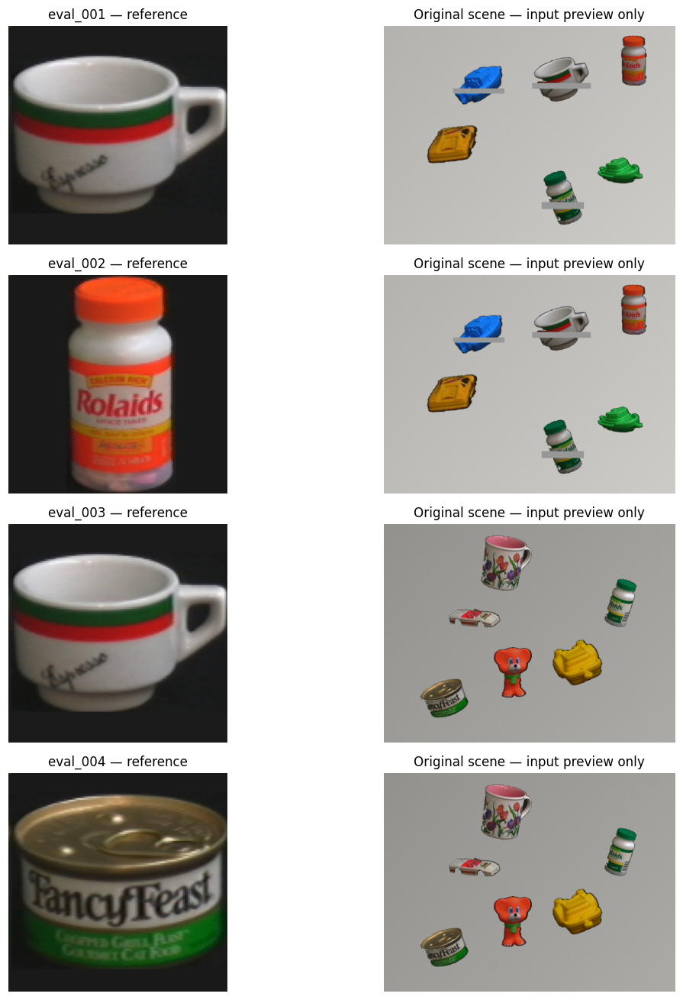

In [20]:
Q3_PREVIEW_START = 0
Q3_PREVIEW_COUNT = 4
preview_pairs = q3_pairs[Q3_PREVIEW_START:Q3_PREVIEW_START + Q3_PREVIEW_COUNT]
if not preview_pairs:
    raise ValueError("Choose a Q3_PREVIEW_START within the pair inventory.")

fig, axes = plt.subplots(
    len(preview_pairs), 2, figsize=(12, 3 * len(preview_pairs)),
    gridspec_kw={"width_ratios": [1, 4]}, squeeze=False,
)
for row, pair in enumerate(preview_pairs):
    reference_rgb, scene_rgb = load_q3_pair(pair)
    axes[row, 0].imshow(reference_rgb)
    axes[row, 0].set_title(f"{pair['pair_id']} — reference")
    axes[row, 1].imshow(scene_rgb)
    axes[row, 1].set_title("Original scene — input preview only")
    del reference_rgb, scene_rgb
for axis in axes.flat:
    axis.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

### Q3.2 — Shared frozen-ViT matching procedure

We use the generic **[DINOv2 ViT-B/14](https://huggingface.co/facebook/dinov2-base)** encoder, pretrained without labels on LVD-142M. The model stays frozen; no classifier or localization head is fitted.

The supplied scenes have a nearly uniform background. A robust color plane fitted to their borders supplies foreground proposals. A short vertical closing groups fragments across horizontal occlusions. This is a scene-specific proposal prior, not a general object detector. Every proposal and reference is cropped to its foreground, placed on a neutral background, and letterboxed to 224×224 without distorting its aspect ratio. RGB is rescaled by 1/255 and channel-normalized with ImageNet mean `[0.485, 0.456, 0.406]` and standard deviation `[0.229, 0.224, 0.225]`.

DINOv2 supplies spatial patch features and its last-layer **CLS-to-patch self-attention**. Foreground-weighted attention pools the patch matches. Symmetric nearest-patch similarity compares both reference-to-candidate and candidate-to-reference coverage; a smaller CLS similarity term adds whole-object context. The other distinct supplied references serve as distractor templates, so matching an arbitrary object of the same category is insufficient.

One shared rule first retains candidates whose similarity is at least **0.60** and whose margin over other reference templates is at least **0.025**, then selects the strongest eligible candidate. These are fixed heuristic thresholds, not calibrated probabilities. All 32 pairs use the same code and settings. Duplicate image bytes reuse inference within this run; no pair-specific answers are stored.

Reference: [Oquab et al., DINOv2](https://github.com/facebookresearch/dinov2), [Transformers DINOv2 documentation](https://huggingface.co/docs/transformers/model_doc/dinov2), and Lecture 9's patch features and attention.

Frozen checkpoint: facebook/dinov2-base @ f9e44c814b77203eaa57a6bdbbd535f21ede1415
SHA-256: d73036b56966966d07975d696bde331762f37297e2f095de8cea0040c3aa0841
CPU float32; one 224×224 crop per inference; 256 spatial patch tokens.


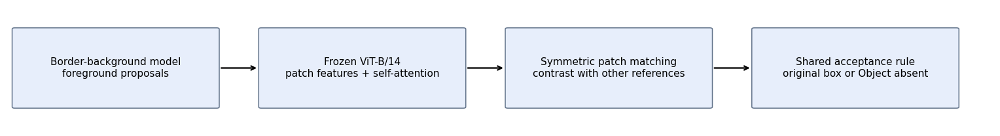

In [21]:
from transformers import Dinov2Model

Q3_MODEL_ID = "facebook/dinov2-base"
Q3_REVISION = "f9e44c814b77203eaa57a6bdbbd535f21ede1415"
Q3_WEIGHTS_SHA256 = "d73036b56966966d07975d696bde331762f37297e2f095de8cea0040c3aa0841"
Q3_MODEL_DIR = PROJECT_ROOT / "outputs" / "models" / f"dinov2_{Q3_REVISION[:12]}"
q3_files = ["config.json", "preprocessor_config.json", "model.safetensors"]
if not all((Q3_MODEL_DIR / name).is_file() for name in q3_files):
    snapshot_download(Q3_MODEL_ID, revision=Q3_REVISION, local_dir=Q3_MODEL_DIR,
                      allow_patterns=q3_files, token=False, max_workers=1)
with (Q3_MODEL_DIR / "model.safetensors").open("rb") as stream:
    q3_weights_hash = hashlib.file_digest(stream, "sha256").hexdigest()
assert q3_weights_hash == Q3_WEIGHTS_SHA256, "DINOv2 checkpoint hash mismatch"
q3_model = Dinov2Model.from_pretrained(Q3_MODEL_DIR, local_files_only=True,
                                      attn_implementation="eager").eval().requires_grad_(False)
assert q3_model.config.patch_size == 14
Q3_MIN_SCORE, Q3_MIN_MARGIN = .60, .025
q3_mean = torch.tensor([.485, .456, .406]).view(1, 3, 1, 1)
q3_std = torch.tensor([.229, .224, .225]).view(1, 3, 1, 1)
print(f"Frozen checkpoint: {Q3_MODEL_ID} @ {Q3_REVISION}")
print(f"SHA-256: {q3_weights_hash}")
print("CPU float32; one 224×224 crop per inference; 256 spatial patch tokens.")
pipeline_diagram(["Border-background model\nforeground proposals",
                  "Frozen ViT-B/14\npatch features + self-attention",
                  "Symmetric patch matching\ncontrast with other references",
                  "Shared acceptance rule\noriginal box or Object absent"])

### Q3.3 — Foreground proposals and coordinate handling

The border model is refitted after rejecting large border residuals. Proposal boxes are measured directly on the original scene foreground, using exclusive right/bottom bounds. Model input transforms record the original crop box, resized dimensions, and padding. For a model-image point `(u,v)`, the inverse is `x=x0+(u-pad_x)*crop_width/resized_width` and similarly for `y`. Patch maps below are shown in model coordinates; final boxes remain in original scene coordinates.

In [22]:
def foreground_mask(rgb, close_shape=(3, 3)):
    """Foreground relative to a robust RGB background plane fitted on the image border."""
    x = rgb.astype(np.float32)/255
    h, w = x.shape[:2]
    yy, xx = np.mgrid[-1:1:complex(h), -1:1:complex(w)]
    design = np.stack([np.ones_like(xx), xx, yy], -1)
    border = np.zeros((h, w), bool); border[:3] = border[-3:] = True
    border[:, :3] = border[:, -3:] = True
    a, b = design[border], x[border]
    keep = np.ones(len(a), bool)
    for _ in range(3):
        coef = np.linalg.lstsq(a[keep], b[keep], rcond=None)[0]
        residual = np.linalg.norm(b - a @ coef, axis=1)
        median = np.median(residual)
        keep = residual <= max(.02, median + 3*1.4826*np.median(np.abs(residual-median)))
    mask = np.linalg.norm(x - design @ coef, axis=2) > .08
    return ndi.binary_fill_holes(ndi.binary_closing(mask, structure=np.ones(close_shape)))


def mask_box(mask):
    ys, xs = np.nonzero(mask)
    if not len(xs):
        raise ValueError("Empty foreground mask")
    return int(xs.min()), int(ys.min()), int(xs.max()+1), int(ys.max()+1)


def scene_proposals(rgb):
    foreground = foreground_mask(rgb, close_shape=(19, 5))
    labels, count = ndi.label(foreground)
    proposals = []
    for index in range(1, count+1):
        mask = labels == index
        if mask.sum() >= 150:
            proposals.append({"mask": mask, "bbox": mask_box(mask)})
    if len(proposals) > 20:
        raise ValueError("More than 20 foreground proposals; inspect the shared background assumption")
    return proposals


@torch.inference_mode()
def encode_q3_object(rgb, mask):
    """Encode one letterboxed foreground crop; retain real attention and spatial descriptors."""
    x0, y0, x1, y1 = mask_box(mask)
    crop = rgb[y0:y1, x0:x1].copy(); local_mask = mask[y0:y1, x0:x1]
    crop[~local_mask] = 128
    ch, cw = crop.shape[:2]; scale = min(224/cw, 224/ch)
    rw, rh = max(1, round(cw*scale)), max(1, round(ch*scale))
    px, py = (224-rw)//2, (224-rh)//2
    canvas = np.full((224, 224, 3), 128, np.uint8)
    canvas[py:py+rh, px:px+rw] = np.array(Image.fromarray(crop).resize((rw, rh), Image.Resampling.BICUBIC))
    mask224 = np.zeros((224, 224), np.float32)
    mask224[py:py+rh, px:px+rw] = np.array(Image.fromarray(local_mask).resize((rw, rh), Image.Resampling.NEAREST))
    pixels = torch.from_numpy(canvas.astype(np.float32)/255).permute(2, 0, 1)[None]
    output = q3_model(pixel_values=(pixels-q3_mean)/q3_std, output_attentions=True)
    features = F.normalize(output.last_hidden_state[0, 1:].float(), dim=-1)
    attention = output.attentions[-1][0].mean(0)[0, 1:].float()
    occupancy = F.avg_pool2d(torch.from_numpy(mask224)[None, None], 14, 14).flatten()
    selected = occupancy > .15
    assert selected.any() and features.shape == (256, 768)
    weights = attention[selected] * occupancy[selected]; weights = weights/weights.sum()
    transform = {"crop_xyxy": (x0, y0, x1, y1), "resized_wh": (rw, rh),
                 "pad_xy": (px, py), "original_wh": (rgb.shape[1], rgb.shape[0])}
    return {"features": features[selected], "weights": weights,
            "cls": F.normalize(output.last_hidden_state[0, 0].float(), dim=-1),
            "attention": attention.reshape(16, 16).numpy(), "selected": selected.numpy(),
            "canvas": canvas, "transform": transform}


@torch.inference_mode()
def q3_similarity(reference, candidate):
    similarity = reference["features"] @ candidate["features"].T
    symmetric = .5*(reference["weights"] @ similarity.max(1).values +
                    candidate["weights"] @ similarity.max(0).values)
    return float(.85*symmetric + .15*(reference["cls"] @ candidate["cls"]))

def choose_q3_candidate(scores, target):
    """Choose the strongest candidate that passes both instance-level gates."""
    if not len(scores):
        return None, 0.0, 0.0, False
    target_scores = scores[:, target]
    margins = target_scores - np.delete(scores, target, axis=1).max(1)
    eligible = (target_scores >= Q3_MIN_SCORE) & (margins >= Q3_MIN_MARGIN)
    index = int(np.argmax(np.where(eligible, target_scores, -np.inf))) if eligible.any() else int(target_scores.argmax())
    return index, float(target_scores[index]), float(margins[index]), bool(eligible[index])

### Q3.4 — Apply the same method to all 32 pairs

Exact duplicate references are merged automatically into one template. Every candidate is compared with every distinct template, without training. A candidate must favor the requested reference over the alternatives. The similarity and margin table makes the shared absence decisions reviewable; low scores are not silently replaced with another object's box.

In [23]:
q3_started = time.perf_counter()
q3_templates, q3_reference_key, q3_scene_cache = {}, {}, {}
for pair in q3_pairs:
    reference, _ = load_q3_pair(pair)
    key = hashlib.sha256(reference.tobytes()).hexdigest()
    q3_reference_key[pair["pair_id"]] = key
    if key not in q3_templates:
        q3_templates[key] = encode_q3_object(reference, foreground_mask(reference))
q3_template_keys = list(q3_templates)
q3_results = []
for pair in q3_pairs:
    _, scene = load_q3_pair(pair)
    scene_key = hashlib.sha256(scene.tobytes()).hexdigest()
    if scene_key not in q3_scene_cache:
        candidates = scene_proposals(scene)
        for candidate in candidates:
            candidate["encoded"] = encode_q3_object(scene, candidate["mask"])
        scores = np.array([[q3_similarity(q3_templates[key], c["encoded"])
                            for key in q3_template_keys] for c in candidates], dtype=np.float32)
        q3_scene_cache[scene_key] = {"candidates": candidates, "scores": scores}
    cached = q3_scene_cache[scene_key]; target = q3_template_keys.index(q3_reference_key[pair["pair_id"]])
    index, score, margin, accepted = choose_q3_candidate(cached["scores"], target)
    bbox = cached["candidates"][index]["bbox"] if accepted else None
    q3_results.append({"pair_id": pair["pair_id"], "bbox": bbox, "score": score,
                       "margin": margin, "scene_key": scene_key, "candidate_index": index,
                       "reference_key": q3_reference_key[pair["pair_id"]]})
q3_seconds = time.perf_counter() - q3_started
show_table([{"pair": r["pair_id"], "result (original coordinates)": r["bbox"] or "Object absent.",
             "similarity": round(r["score"], 3), "reference margin": round(r["margin"], 3)}
            for r in q3_results], ["pair", "result (original coordinates)", "similarity", "reference margin"])
print(f"{len(q3_results)} pairs; {len(q3_templates)} distinct references; {len(q3_scene_cache)} distinct scenes; {q3_seconds:.2f}s CPU.")

| pair | result (original coordinates) | similarity | reference margin |
| --- | --- | --- | --- |
| eval_001 | (407, 87, 568, 210) | 0.783 | 0.37 |
| eval_002 | (651, 28, 721, 165) | 0.947 | 0.091 |
| eval_003 | Object absent. | 0.479 | -0.395 |
| eval_004 | (100, 425, 232, 532) | 0.862 | 0.046 |
| eval_005 | (525, 70, 690, 197) | 0.849 | 0.028 |
| eval_006 | Object absent. | 0.869 | -0.087 |
| eval_007 | Object absent. | 0.82 | -0.028 |
| eval_008 | Object absent. | 0.471 | -0.358 |
| eval_009 | (356, 469, 491, 543) | 0.719 | 0.106 |
| eval_010 | Object absent. | 0.476 | -0.017 |
| eval_011 | Object absent. | 0.618 | -0.101 |
| eval_012 | Object absent. | 0.51 | 0.008 |
| eval_013 | (251, 301, 344, 436) | 0.854 | 0.059 |
| eval_014 | Object absent. | 0.809 | -0.027 |
| eval_015 | Object absent. | 0.831 | -0.07 |
| eval_016 | Object absent. | 0.435 | -0.411 |
| eval_017 | (414, 221, 544, 343) | 0.848 | 0.385 |
| eval_018 | Object absent. | 0.4 | -0.125 |
| eval_019 | Object absent. | 0.512 | -0.318 |
| eval_020 | Object absent. | 0.439 | -0.025 |
| eval_021 | (263, 90, 414, 209) | 0.884 | 0.045 |
| eval_022 | (434, 150, 559, 245) | 0.891 | 0.418 |
| eval_023 | Object absent. | 0.806 | -0.017 |
| eval_024 | (463, 319, 620, 483) | 0.835 | 0.366 |
| eval_025 | (403, 516, 548, 572) | 0.7 | 0.112 |
| eval_026 | Object absent. | 0.781 | -0.029 |
| eval_027 | Object absent. | 0.577 | -0.06 |
| eval_028 | Object absent. | 0.219 | -0.269 |
| eval_029 | (121, 249, 204, 374) | 0.872 | 0.045 |
| eval_030 | Object absent. | 0.659 | -0.099 |
| eval_031 | Object absent. | 0.852 | -0.07 |
| eval_032 | Object absent. | 0.428 | -0.377 |

32 pairs; 8 distinct references; 16 distinct scenes; 10.12s CPU.


### Q3.5 — Intermediate attention and matching evidence

For the first three pairs, show the requested reference, the chosen candidate's letterboxed RGB model input, its actual foreground-gated CLS-attention pooling weights, and its spatial patch-to-reference similarity. Similarity uses foreground-weighted self-attention in both directions. These diagnostics show the candidate even when the acceptance rule rejects it; a bright patch alone is not an instance-level match.

Raw DINOv2 CLS attention can emphasize background tokens. The displayed map applies the same foreground occupancy gate and normalization as the matching code; it sums to one over the retained patches.

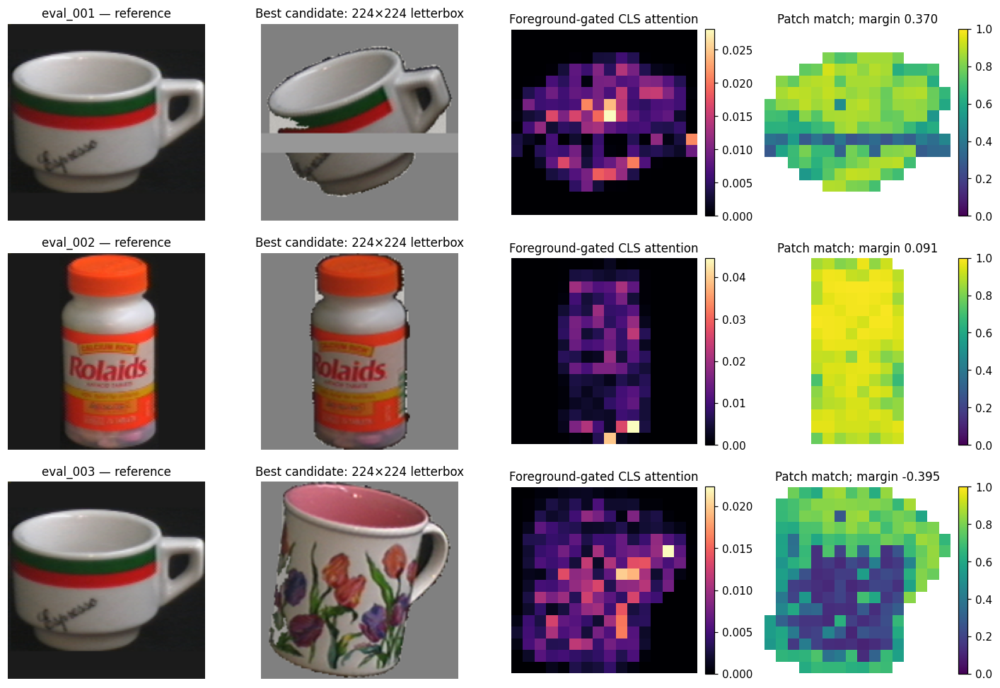

In [24]:
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for row, result in enumerate(q3_results[:3]):
    pair = q3_pairs[row]; reference, _ = load_q3_pair(pair)
    axes[row, 0].imshow(reference); axes[row, 0].set_title(f"{result['pair_id']} — reference")
    candidates = q3_scene_cache[result["scene_key"]]["candidates"]
    if result["candidate_index"] is None:
        for axis in axes[row, 1:]: axis.text(.5, .5, "No foreground proposal", ha="center")
        continue
    candidate = candidates[result["candidate_index"]]["encoded"]
    target = q3_templates[result["reference_key"]]
    similarities = (candidate["features"] @ target["features"].T).max(1).values.numpy()
    spatial_map = np.full(256, np.nan); spatial_map[candidate["selected"]] = similarities
    axes[row, 1].imshow(candidate["canvas"]); axes[row, 1].set_title("Best candidate: 224×224 letterbox")
    pooling_map = np.zeros(256); pooling_map[candidate["selected"]] = candidate["weights"].numpy()
    a = axes[row, 2].imshow(pooling_map.reshape(16, 16), cmap="magma"); axes[row, 2].set_title("Foreground-gated CLS attention")
    fig.colorbar(a, ax=axes[row, 2], fraction=.046, pad=.04)
    m = axes[row, 3].imshow(spatial_map.reshape(16, 16), cmap="viridis", vmin=0, vmax=1)
    axes[row, 3].set_title(f"Patch match; margin {result['margin']:.3f}")
    fig.colorbar(m, ax=axes[row, 3], fraction=.046, pad=.04)
for axis in axes.flat: axis.axis("off")
fig.tight_layout(); plt.show(); plt.close(fig)

### Q3.6 — Final results for every pair

Each original 800×600 scene is shown beside its reference. A green rectangle marks the predicted visible-extent box; otherwise the title reports **"Object absent."** Coordinates use exclusive right/bottom bounds. Figures are split into groups of four for readability.

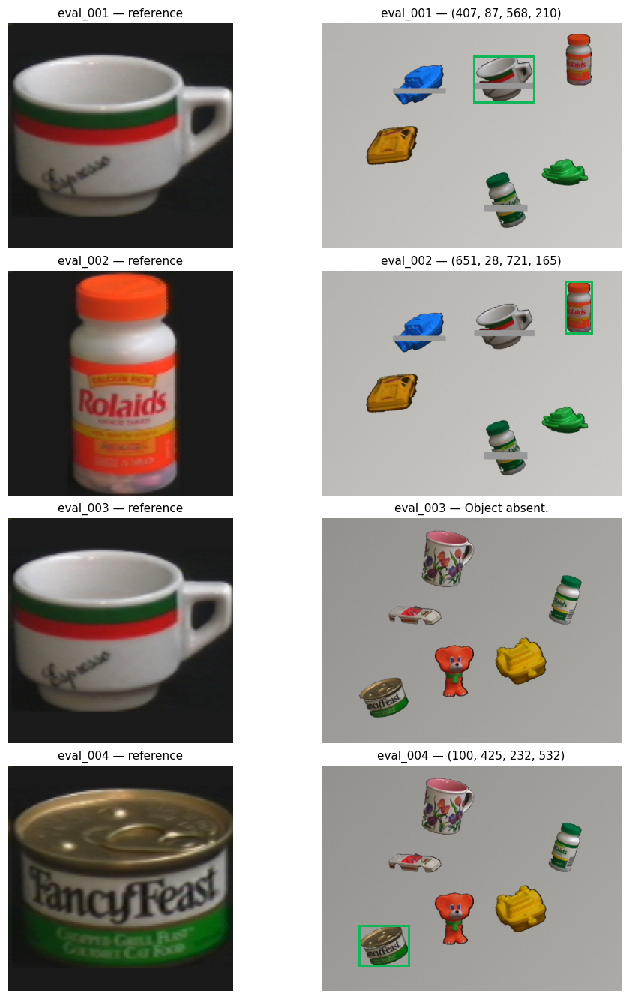

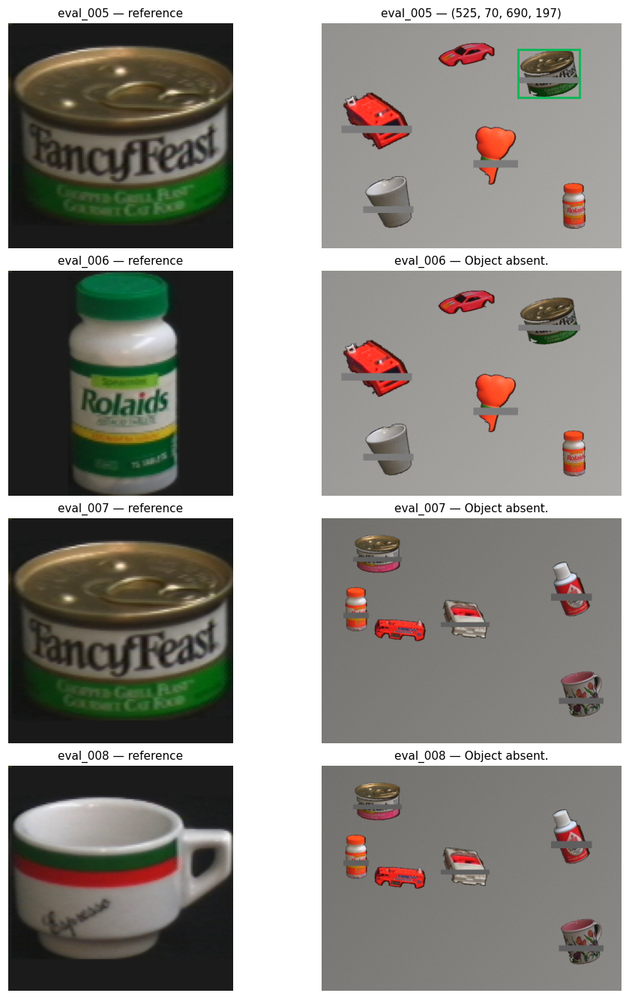

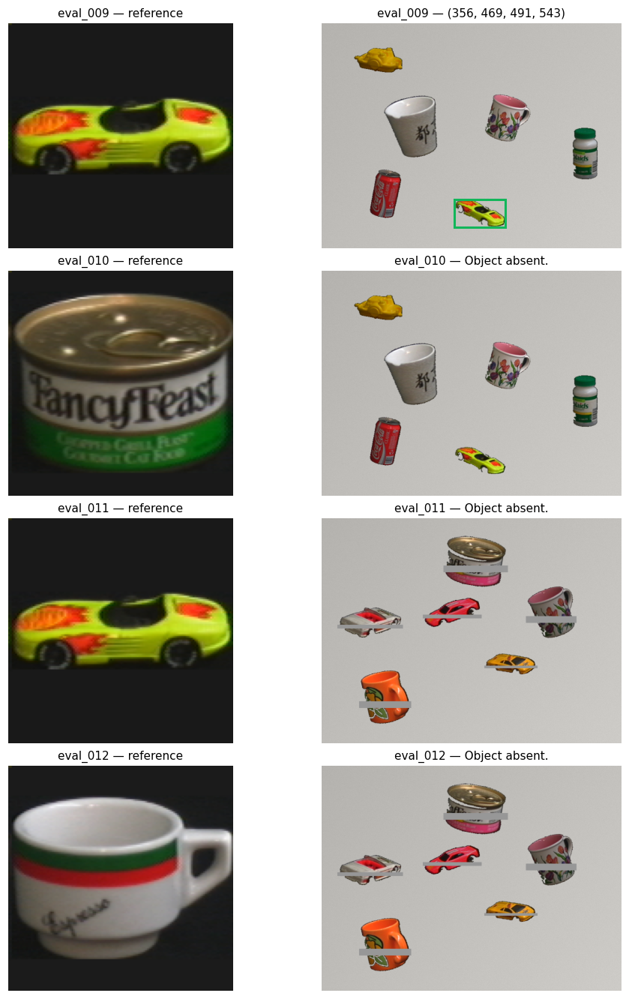

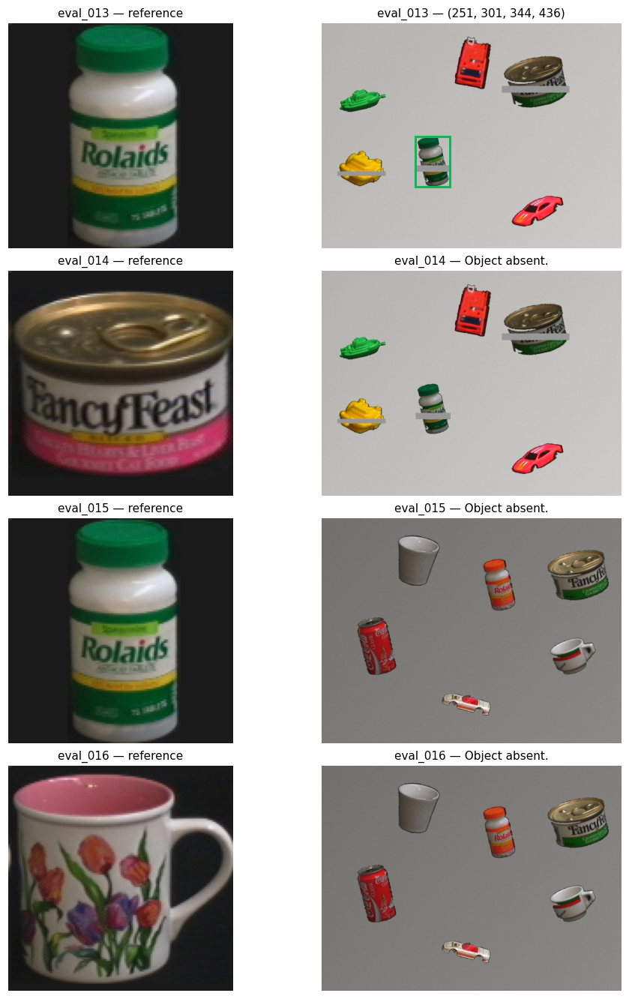

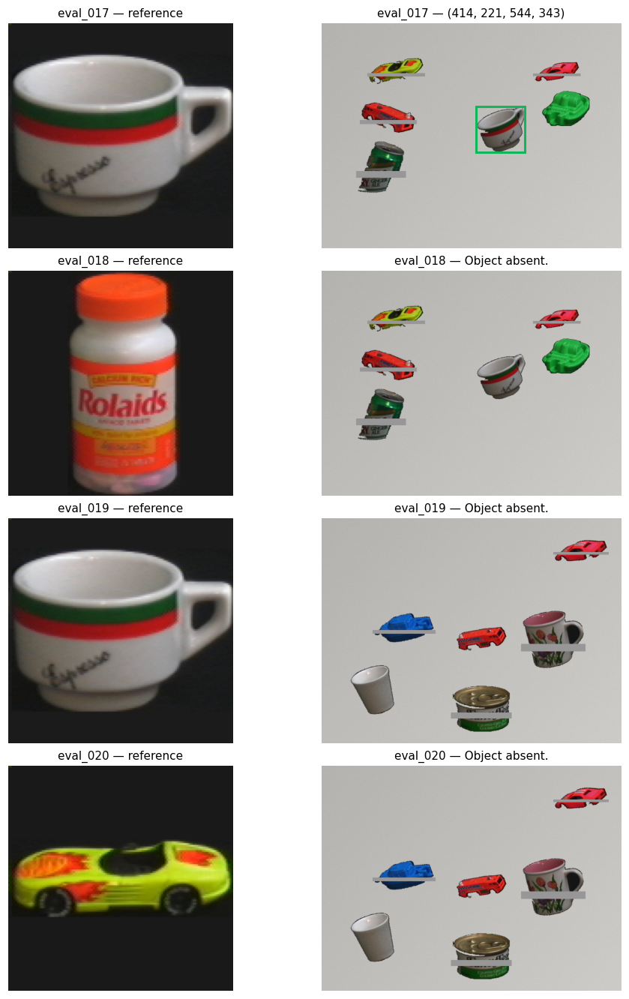

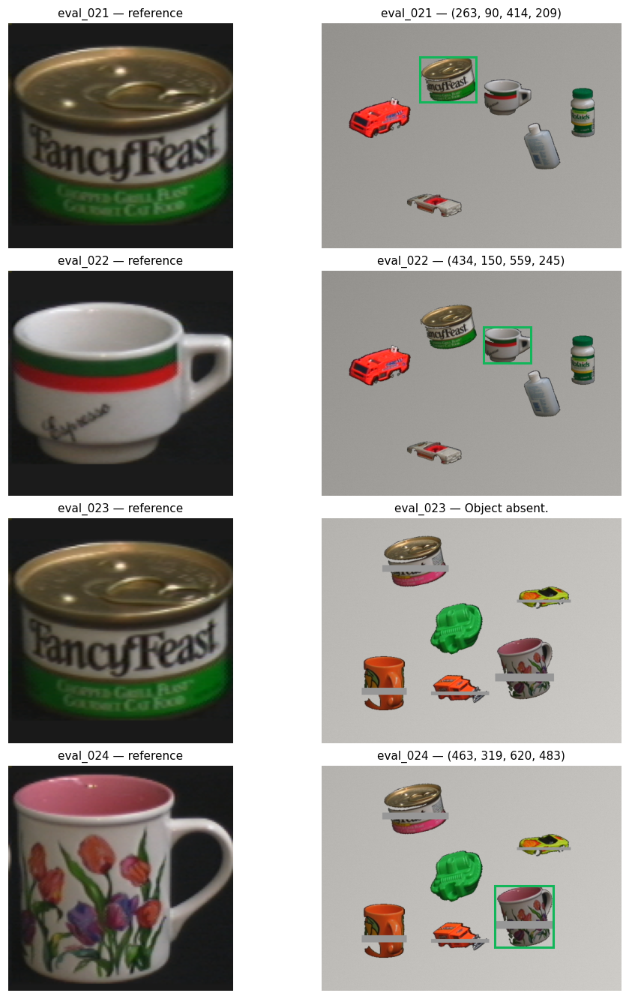

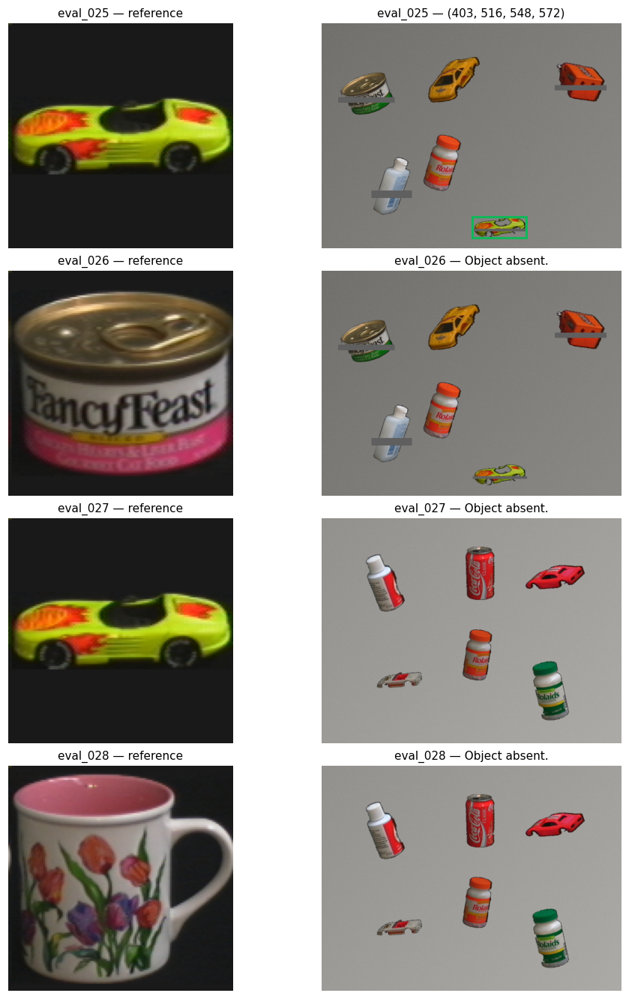

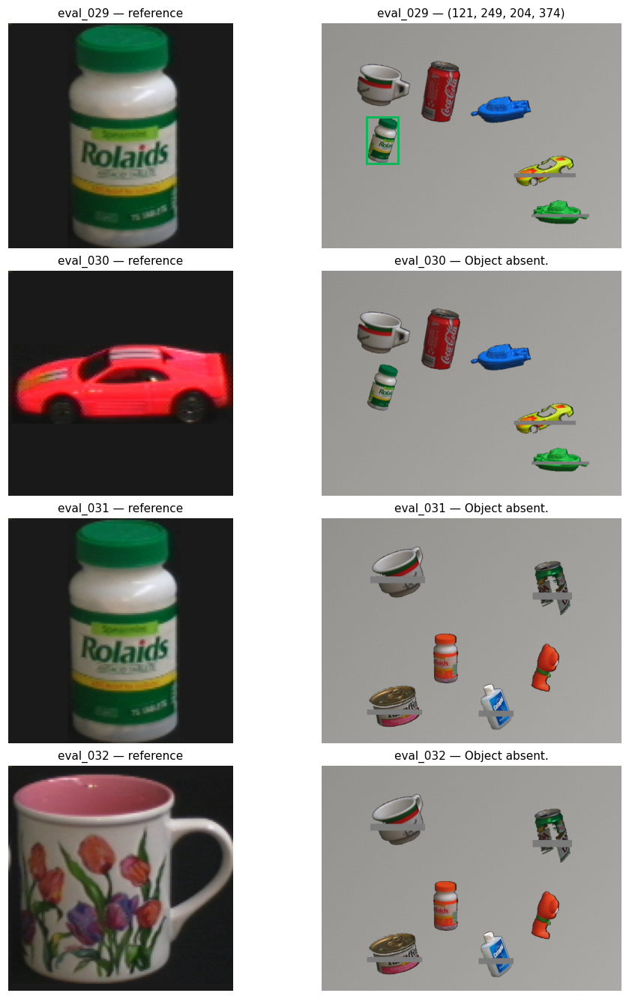

In [25]:
for start in range(0, len(q3_pairs), 4):
    fig, axes = plt.subplots(4, 2, figsize=(8.5, 12),
                             gridspec_kw={"width_ratios": [1, 4/3]}, layout="constrained")
    for row, (pair, result) in enumerate(zip(q3_pairs[start:start+4], q3_results[start:start+4])):
        reference, scene = load_q3_pair(pair)
        axes[row, 0].imshow(reference); axes[row, 0].set_title(f"{pair['pair_id']} — reference", fontsize=10)
        axes[row, 1].imshow(scene, extent=(0, 800, 600, 0))
        box = result["bbox"]
        if box is not None:
            x0, y0, x1, y1 = box
            axes[row, 1].add_patch(Rectangle((x0, y0), x1-x0, y1-y0, fill=False, edgecolor="#12b65a", lw=2))
        axes[row, 1].set_title(f"{pair['pair_id']} — {box if box is not None else 'Object absent.'}", fontsize=10)
    for axis in axes.flat: axis.axis("off")
    plt.show(); plt.close(fig)

### Q3.7 — Contract checks and limitations

Check all 32 IDs, original-coordinate bounds, letterbox transform round trips, normalized pooling weights, and frozen parameters. Similarities and margins are heuristic evidence, not detection probabilities. No bounding-box or absence ground truth was supplied, so numerical localization accuracy and IoU are unknown.

The background-plane proposal prior is appropriate to these supplied tabletop scenes. Cluttered backgrounds, merged objects, strong shadows, or an occlusion that disconnects an object can break proposals. Similar containers with weak distinguishing texture remain difficult; reference contrast reduces this ambiguity but does not guarantee identity.

In [26]:
assert [r["pair_id"] for r in q3_results] == [p["pair_id"] for p in q3_pairs]
assert len(q3_results) == 32 and not q3_model.training
assert not any(p.requires_grad for p in q3_model.parameters())
for result in q3_results:
    if result["bbox"] is not None:
        x0, y0, x1, y1 = result["bbox"]
        assert 0 <= x0 < x1 <= 800 and 0 <= y0 < y1 <= 600
        assert result["score"] >= Q3_MIN_SCORE and result["margin"] >= Q3_MIN_MARGIN
for encoded in list(q3_templates.values()) + [c["encoded"] for s in q3_scene_cache.values() for c in s["candidates"]]:
    assert np.isfinite(encoded["attention"]).all() and np.isclose(float(encoded["weights"].sum()), 1)
    t = encoded["transform"]; x0, y0, x1, y1 = t["crop_xyxy"]
    rw, rh = t["resized_wh"]; px, py = t["pad_xy"]
    original = np.array([[x0, y0], [x1, y1]], float)
    model_xy = (original - [x0, y0]) * [rw/(x1-x0), rh/(y1-y0)] + [px, py]
    restored = (model_xy - [px, py]) * [(x1-x0)/rw, (y1-y0)/rh] + [x0, y0]
    assert np.allclose(restored, original), "Letterbox coordinate round trip failed"
identity_scores = np.array([[q3_similarity(a, b) for b in q3_templates.values()] for a in q3_templates.values()])
assert np.allclose(np.diag(identity_scores), 1, atol=1e-5)
assert np.array_equal(identity_scores.argmax(1), np.arange(len(identity_scores))), "Reference identities collapsed"
print(f"All 32 results passed ID/bounds checks; {sum(r['bbox'] is None for r in q3_results)} absent predictions.")
print("Letterbox transforms, finite attention, normalized pooling, and frozen-weight checks passed.")
# A high-scoring distractor must not hide a lower-scoring valid target candidate.
assert choose_q3_candidate(np.array([[.90, .95], [.82, .65]]), 0)[0] == 1
assert choose_q3_candidate(np.array([[.50, .60]]), 0)[3] is False
assert choose_q3_candidate(np.empty((0, 2)), 0)[0] is None
print("Eligible-candidate selection, rejection, and empty-scene cases passed.")

All 32 results passed ID/bounds checks; 20 absent predictions.
Letterbox transforms, finite attention, normalized pooling, and frozen-weight checks passed.
Eligible-candidate selection, rejection, and empty-scene cases passed.


## Results and execution record

All three question sections contain implemented methods, saved visual outputs, and contract checks. The checks establish implementation correctness; no clean-image or localization ground truth is available for numerical accuracy scoring.

In [27]:
if (len(q1_samples), len(q2_samples), len(q3_pairs)) != (3, 3, 32):
    raise ValueError("Input collections are incomplete; rerun the loading cells.")

show_table([
    {"question": "Q1", "inputs": "3 masked images + 3 supplied masks",
     "data": "Validated", "solution": f"Complete — {len(q1_results)} reconstructions; checks passed"},
    {"question": "Q2", "inputs": "3 complete noisy RGB images",
     "data": "Validated", "solution": f"Complete — {len(q2_results)} denoised images + attention maps"},
    {"question": "Q3", "inputs": "32 reference/scene pairs",
     "data": "Validated", "solution": f"Complete — {len(q3_results)} localization/absence results"},
], ["question", "inputs", "data", "solution"])
assert len(q1_results) == len(q1_checks) == 3
assert len(q2_results) == len(q2_checks) == 3 and len(q3_results) == 32
print("Q1–Q3 methods and requested visual outputs are complete; finalize submission metadata below.")

| question | inputs | data | solution |
| --- | --- | --- | --- |
| Q1 | 3 masked images + 3 supplied masks | Validated | Complete — 3 reconstructions; checks passed |
| Q2 | 3 complete noisy RGB images | Validated | Complete — 3 denoised images + attention maps |
| Q3 | 32 reference/scene pairs | Validated | Complete — 32 localization/absence results |

Q1–Q3 methods and requested visual outputs are complete; finalize submission metadata below.


### Progress — November 19, 2026

**Initial scaffold:** 16 code cells ran in a fresh kernel with zero errors; all 73 input images decoded successfully. The three data collections and input previews were prepared without changing raw files.

**Q1 implementation and verification:** a fresh-kernel run executed all 20 code cells with zero errors in 34.37 seconds, including the first checkpoint download. Three reconstruction passes took 0.27 seconds on CPU. All three images used exactly 98 visible patches (99 encoder tokens including CLS), changed zero visible pixels, and had zero raw-prediction change after randomizing hidden input pixels. The flow diagram, intermediate outputs, and final pairs were visually inspected. All 85 protected input/Q4/project files remained unchanged. Checkpoint identity, hash, preprocessing, versions, runtime, and outcomes are recorded beside the code. Q2 and Q3 were implemented subsequently; see the current record below.

**Q2–Q3 development:** Q2 uses explicit local patch attention, real-weight heatmaps, and full-image overlap reconstruction. A denser stride-2 pass and lower matching bandwidth retained more detail than the initial stride-4 preview; no clean-target quality metric was used. Q3 uses frozen DINOv2 features and self-attention on shared foreground proposals, with exact-image deduplication. The initial 0.78 absolute floor was overly conservative under viewpoint changes during visual development review; the final shared floor is 0.60 with a 0.025 distractor margin. These thresholds are development heuristics, not independently calibrated accuracy claims. No pair-specific labels or coordinates were entered, and no model was trained.

**Final Q1–Q3 verification:** fresh-kernel restart-and-run-all completed 27 code cells with zero errors in 25.24 seconds. All 19 figures are saved. Q2 processed the three complete images in 3.13s; its largest selected-patch replay error was 3.58e-07, and coverage/weight/constant-color checks passed. Q3 processed all 32 pairs in 10.12s, reusing 8 distinct references and 16 scenes; the shared rule predicted 12 boxes and 20 absences. All ID, box-bound, coordinate-transform, reference-identity, frozen-weight, candidate-rejection, and empty-candidate checks passed. New figures, including all 32 result panels, were visually reviewed. All 85 protected files (raw inputs, existing Q4 work, and project metadata) retained their SHA-256 hashes. Q1 source is preserved. Prediction counts and implementation checks are not accuracy measurements.

### Final submission checklist

- [ ] Enter current team member names and NetIDs at the top.
- [x] Q1: all three reconstructed images, model identity, and unchanged visible pixels.
- [x] Q2: all three denoised images, actual attention heatmaps, and explanations.
- [x] Q3: frozen ViT spatial features and self-attention; all 32 boxes/absence outputs in original coordinates.
- [x] Record methods, provenance, measured runtimes, and implementation checks for Q2 and Q3.
- [ ] Include the actual AI chat-history link or PDF.
- [x] Restart the runtime, run every cell in order, inspect results, and save outputs intact (repeat if code changes).
- [ ] Submit both this executed `.ipynb` file and a shareable view link on Brightspace.

**Next step:** review all final figures and fill the remaining submission metadata.